# 06 · Problem identification

## Purpose

Turn computed data-quality and association outputs into evidence-based research questions, without assuming that the dataset must show an effect.

## Method

Summarize observed return prevalence, imbalance, significant adjusted associations, data limitations, and the prediction-time policy. Print findings directly from the active data and test table.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

The dataset is observational and may be synthetic or competition-generated. Its associations do not establish customer or product causes.

## References

See docs/references.md for the method map and novelty boundary.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '06 · Problem identification')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 06 · Problem identification


Observed rows: 200,000; columns: 16; exact duplicate rows: 0.
Observed target proportions:


,proportion
returned,
0,0.525405
1,0.474595


Features with BH-adjusted p < 0.05: 10 of 11 tested.


,feature,test,effect_size,effect_label,p_adjusted_bh
0,product_category,Pearson chi-square,0.076458,Cramer's V,1.542886e-249
1,shipping_method,Pearson chi-square,0.069611,Cramer's V,1.970436e-210
2,payment_method,Pearson chi-square,0.060810,Cramer's V,2.017260e-159
3,device_type,Pearson chi-square,0.056712,Cramer's V,5.759899e-140
4,used_coupon,Pearson chi-square,0.054950,Cramer's V,5.246192e-133
5,product_price,Mann-Whitney U (two-sided),0.046222,rank-biserial correlation,3.170087e-71
6,num_product_views,Mann-Whitney U (two-sided),-0.023158,rank-biserial correlation,5.081386e-19
7,session_length_minutes,Mann-Whitney U (two-sided),-0.020484,rank-biserial correlation,3.180208e-15
8,discount_percent,Mann-Whitney U (two-sided),0.012981,rank-biserial correlation,6.286414e-07
9,customer_age,Mann-Whitney U (two-sided),-0.012683,rank-biserial correlation,1.020405e-06


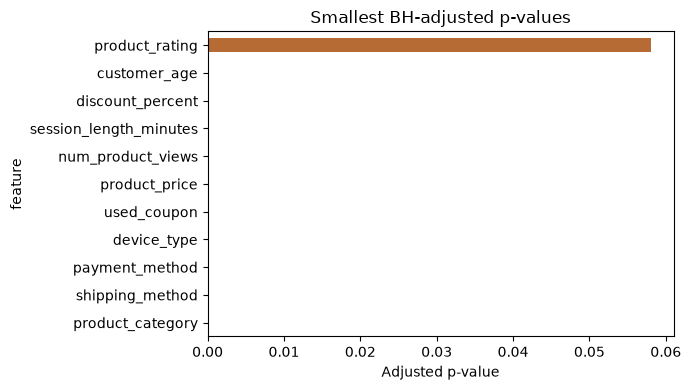

Prediction timing: pre-shipment. No temporal validation is claimed without transaction event-order timestamps.
Candidate research questions: (1) Do available pre-shipment features distinguish return risk? (2) Are model probabilities reliable? (3) Does review prioritization improve expected outcomes under stated costs and capacity?
Operational impact is a hypothesis for scenario analysis, not a measured business effect.


,feature,availability_assessment,decision
0,customer_age,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
1,product_price,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
2,discount_percent,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
3,product_rating,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
4,past_purchase_count,historical aggregate; event order and cutoff u...,exclude until leakage-safe construction is ver...
5,past_return_rate,historical aggregate; event order and cutoff u...,exclude until leakage-safe construction is ver...
6,delivery_delay_days,post-shipment outcome,exclude from pre-shipment prediction
7,session_length_minutes,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
8,num_product_views,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
9,device_type,likely available by order placement; verify wi...,eligible for pre-shipment candidate set


In [2]:
from returnwise.analysis.statistics import association_tests
from returnwise.data.profile import quality_report
from returnwise.features import select_features, temporal_feature_audit
from returnwise.storage import load_active_dataset
import matplotlib.pyplot as plt

frame, manifest = load_active_dataset()
if frame is None:
    raise RuntimeError('No active dataset. Complete notebook 01 first.')
quality = quality_report(frame)
print(f'Observed rows: {len(frame):,}; columns: {len(frame.columns):,}; exact duplicate rows: {quality["duplicate_rows"]:,}.')
if 'returned' in frame:
    print('Observed target proportions:')
    display(frame['returned'].value_counts(normalize=True, dropna=False).rename('proportion').to_frame())
    candidate_features = select_features(frame, scenario='pre_shipment')
    tests = association_tests(frame[candidate_features + ['returned']])
    if not tests.empty:
        supported = tests[tests['significant_fdr_0_05']]
        print(f'Features with BH-adjusted p < 0.05: {len(supported)} of {len(tests)} tested.')
        display(supported[['feature', 'test', 'effect_size', 'effect_label', 'p_adjusted_bh']])
        chart = tests.set_index('feature')['p_adjusted_bh'].sort_values().head(15)
        ax = chart.plot.barh(figsize=(7, 4), color='#B56B33', title='Smallest BH-adjusted p-values')
        ax.set_xlabel('Adjusted p-value')
        plt.tight_layout()
        plt.show()
    else:
        print('No eligible feature-target association tests were available.')
else:
    print('No target is available, so return-risk research questions cannot be evaluated.')
print('Prediction timing: pre-shipment. No temporal validation is claimed without transaction event-order timestamps.')
print('Candidate research questions: (1) Do available pre-shipment features distinguish return risk? (2) Are model probabilities reliable? (3) Does review prioritization improve expected outcomes under stated costs and capacity?')
print('Operational impact is a hypothesis for scenario analysis, not a measured business effect.')
display(temporal_feature_audit(list(frame.columns)))
